In [9]:
import pandas as pd
# Install spacy
## -q is for "quiet". It removes logs
%pip install spacy -q
# Import spacy, if you don't have it --> !pip install spacy
import spacy
spacy.__version__
# Download model
!python -m spacy download en_core_web_sm -q
# Import english stop words
from spacy.lang.en.stop_words import STOP_WORDS

Note: you may need to restart the kernel to use updated packages.
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [10]:
data = pd.read_csv(r'C:\Users\LN\Documents\Jedha\Projets\NORTH_FACE\Helene\data\sample_clean.csv')

In [11]:
import en_core_web_sm
nlp = en_core_web_sm.load() 
docs = list(nlp.pipe(data['products'].astype(str)))
for doc in docs:

# Print tokens
    print("Tokens: {}".format([token.text for token in doc]))
    print("------------")

    # Print Lemmatized tokens
    print("Lemma: {}".format([token.lemma_ for token in doc]))
    print("------------")

    # Print Indices of each tokens
    print("Indices: {}".format([token.i for token in doc]))
    print("------------")

    # Print whether tokens are alpha numeric
    print("Alpha Numeric: {}".format([token.is_alpha for token in doc]))
    print("------------")

    # Print whether tokens are numbers
    print("Numbers: {}".format([token.like_num for token in doc]))

# Ajouter des stop words personnalisés
nlp.Defaults.stop_words.update({"and", "the", "a", "for", "in", "to", "of", "is", "on", "from"})

# Appliquer les modifications au vocabulaire
for word in {"and", "the", "a", "for", "in", "to", "of", "is", "on", "from"}:
    nlp.vocab[word].is_stop = True

Tokens: ['Active', 'classic', 'boxers']
------------
Lemma: ['active', 'classic', 'boxer']
------------
Indices: [0, 1, 2]
------------
Alpha Numeric: [True, True, True]
------------
Numbers: [False, False, False]
Tokens: ['Active', 'sport', 'boxer', 'briefs']
------------
Lemma: ['active', 'sport', 'boxer', 'brief']
------------
Indices: [0, 1, 2, 3]
------------
Alpha Numeric: [True, True, True, True]
------------
Numbers: [False, False, False, False]
Tokens: ['Active', 'sport', 'briefs']
------------
Lemma: ['active', 'sport', 'brief']
------------
Indices: [0, 1, 2]
------------
Alpha Numeric: [True, True, True]
------------
Numbers: [False, False, False]
Tokens: ['Alpine', 'guide', 'pants']
------------
Lemma: ['alpine', 'guide', 'pant']
------------
Indices: [0, 1, 2]
------------
Alpha Numeric: [True, True, True]
------------
Numbers: [False, False, False]
Tokens: ['Alpine', 'wind', 'jkt']
------------
Lemma: ['alpine', 'wind', 'jkt']
------------
Indices: [0, 1, 2]
------------

In [12]:
# Print stop words
print(STOP_WORDS)

{'both', 'us', 'quite', 'she', 'say', 'otherwise', 'out', 'yourselves', 'whereby', 'yourself', 'anyone', 'is', 'that', 'namely', 'cannot', 'not', 'become', 'various', 'behind', 'always', 'thereby', 'does', 'former', 'what', 'herein', 'should', 'might', 'anywhere', 'toward', 'anything', 'call', '‘m', 'latterly', 'became', 'under', 'beyond', 'there', 'show', '’d', 'n’t', 'twenty', 'five', 'for', 'regarding', 'within', 'hereafter', 'during', 'whoever', 'although', 'three', 'get', 'which', 'front', 'now', 'fifty', 'nobody', 'indeed', 'several', 'put', '‘re', 'sometimes', 'upon', 'afterwards', 'seeming', 'hundred', 'he', 'one', 'amongst', 'above', 'be', 'please', '‘s', "'re", 'therefore', 'everything', 'between', 'thereafter', "'ve", 'himself', 'against', 'made', 'over', 'until', 'more', 'its', 'up', 'after', 'this', 'were', 'only', 'forty', 'everywhere', 'other', 'her', 'have', 'seem', 'these', 'once', 'ca', '’ll', '’re', 'each', 'the', 'at', 'often', 'see', 'could', 'doing', 'it', 'itself

In [13]:
# Install wordcloud if necessary
# %pip install wordcloud -q

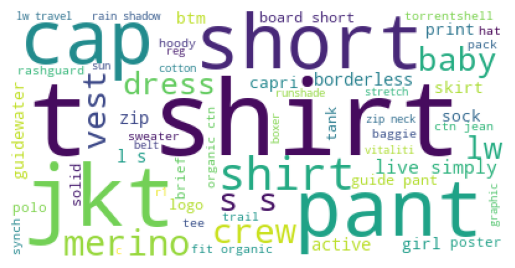

In [14]:
import re
# Import matplotlib and wordcloud
import matplotlib.pyplot as plt
import wordcloud
from spacy.lang.en.stop_words import STOP_WORDS

text = " ".join(data['products'].astype(str))
text = re.sub(r"<[^>]+>", " ", text) # replace html
text = re.sub(r"[!\"#$%&()*+,-./:;<=>?@[\\\]^_`{|}~]+", " ", text).lower() # lowercase and punctuation
text = re.sub(r" {2,}", " ", text).strip(" ") # remove concatened spaces and spaces before and after strings

doc = nlp(text)
lemma = [token.lemma_ for token in doc if token.lemma_ not in STOP_WORDS]
lemma

cloud = wordcloud.WordCloud(
    stopwords=STOP_WORDS, 
    collocations=True, # remove bigrams
    min_font_size=6,
    background_color="white", 
    colormap="viridis"
).generate(" ".join(lemma)) # remove stopwords

# Show word cloud with matplotlib
plt.imshow(cloud)
plt.axis("off")

# Remove trailing logs
plt.show()

In [15]:
from collections import Counter; Counter(lemma).most_common(30)

[('shirt', 99),
 ('t', 76),
 ('jkt', 45),
 ('pant', 43),
 ('short', 42),
 ('cap', 36),
 ('s', 36),
 ('1', 21),
 ('2', 18),
 ('lw', 16),
 ('zip', 15),
 ('simply', 15),
 ('merino', 15),
 ('guide', 14),
 ('crew', 14),
 ('vest', 13),
 ('organic', 13),
 ('baby', 12),
 ('dress', 11),
 ('live', 11),
 ('active', 10),
 ('borderless', 10),
 ('l', 10),
 ('print', 9),
 ('btm', 9),
 ('girl', 9),
 ('guidewater', 9),
 ('sock', 9),
 ('skirt', 9),
 ('3', 8)]

La taille d’un mot dépend de sa fréquence dans le texte : plus il est gros, plus il apparaît souvent. La position, l’orientation et la couleur sont aléatoires et n’ont aucune signification. dwr signifie Durable Water Repellent. g pourrait mesurer le poids. 

Prochaines étapes 
puis data mining avec tf idf
retirer le bruit

In [16]:
# # import displacy
# from spacy import displacy

# # render displacy
# sample = nlp(data['description'].astype(str).iloc[0])
# displacy.render(list(sample.sents)[0], style='dep', jupyter=True,options={'distance': 70})

# text mining

## create an array of odcuments

In [17]:
type(lemma)

list

In [18]:
import pandas as pd
series = pd.Series(lemma)

In [19]:
series = pd.Series([" ".join(token.lemma_ for token in d if token.lemma_ not in STOP_WORDS) for d in docs])
df = pd.DataFrame(series, columns=["catalogue"])

In [20]:
df.value_counts() > 50

catalogue                   
Watermaster wader               False
torrentshell pant               False
shop pant                       False
riverwalker                     False
live simply guitar t - shirt    False
                                ...  
Vitaliti skirt                  False
Vitaliti dress                  False
Versatiliti tee                 False
Versatiliti tank                False
wyoming climbing poster         False
Name: count, Length: 417, dtype: bool

In [21]:
type(df)

pandas.core.frame.DataFrame

In [22]:
df.head()

,catalogue
0,active classic boxer
1,active sport boxer brief
2,active sport brief
3,alpine guide pant
4,alpine wind jkt


In [23]:
# Tfidf transformer
from sklearn.feature_extraction.text import TfidfVectorizer

# TF-IDF vector
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df['catalogue'])

# X is a generator. We can transform that as an array
dense = X.toarray()
dense


array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(500, 378))

In [24]:
# Creating a DataFrame with all the words and tf-idf score
tfid_df = pd.DataFrame(dense,
                        columns=[x for x in vectorizer.get_feature_names_out()])

tfid_df

,100,11,19,21,73,accord,active,adour,alaska,alpine,...,web,wheat,wheelie,wild,wind,world,wrap,wyoming,yosemite,zip
0,0.0,0.0,0.0,0.0,0.0,0.0,0.517688,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.453242,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.527011,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.705874,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.650245,...,0.0,0.0,0.0,0.0,0.650245,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
496,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
497,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
498,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0


In [25]:
# Transpose dataframe
tfid_df = tfid_df.T

# Create a new token column
tfid_df["token"] = tfid_df.index

tfid_df

,0,1,2,3,4,5,6,7,8,9,...,491,492,493,494,495,496,497,498,499,token
100,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100
11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11
19,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,19
21,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,21
73,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.734164,0.0,0.0,0.0,0.0,0.0,0.0,0.0,73
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
world,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,world
wrap,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,wrap
wyoming,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,wyoming
yosemite,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,yosemite


In [26]:
# Sort the top 15 values by descending order
tfid_df.sort_values(by=0, ascending=False)[:15]

,0,1,2,3,4,5,6,7,8,9,...,491,492,493,494,495,496,497,498,499,token
classic,0.626367,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,classic
boxer,0.582807,0.510255,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.610191,0.000000,0.0,0.0,0.0,0.0,0.0,boxer
active,0.517688,0.453242,0.527011,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.542012,0.684139,0.0,0.0,0.0,0.0,0.0,active
100,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,100
reversible,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,reversible
runner,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,runner
roy,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,roy
rockpile,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,rockpile
rock,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,rock
roam,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.676944,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,roam


In [27]:
# Import plotly express
import plotly.express as px

# Create bar chart
fig = px.bar(tfid_df.sort_values(by=0, ascending=False)[:15], x="token", y=0)

# Render chart
fig.show()